In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA

faces = fetch_olivetti_faces(shuffle=True, random_state=32)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /Users/kimsoonho/scikit_learn_data


In [5]:
faces.keys()

dict_keys(['data', 'images', 'target', 'DESCR'])

In [6]:
faces['data'].shape

(400, 4096)

In [8]:
faces['target'].shape

(400,)

In [10]:
X = faces.data
images = faces.images
person = faces.target

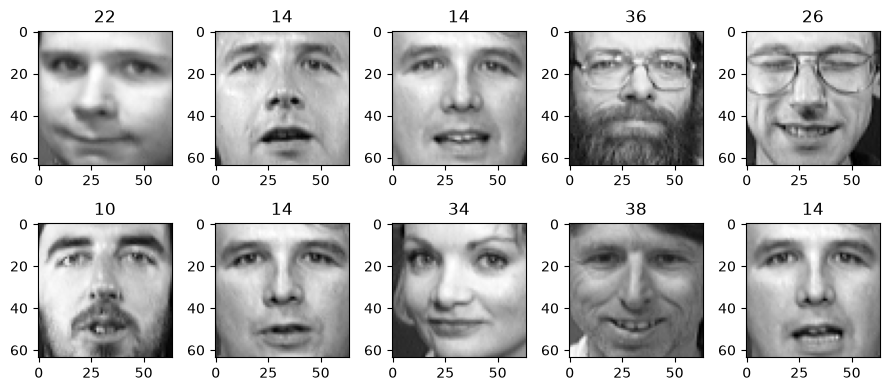

In [13]:
fig, axes = plt.subplots(2, 5, figsize = (9,4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap='gray')
    ax.set_title(person[i])

plt.tight_layout()
plt.show()

In [14]:
images.shape

(400, 64, 64)

In [15]:
X.shape

(400, 4096)

In [18]:
images[0].shape

(64, 64)

In [21]:
images[0].flatten().shape

(4096,)

In [22]:
X[0].reshape(64,64).shape

(64, 64)

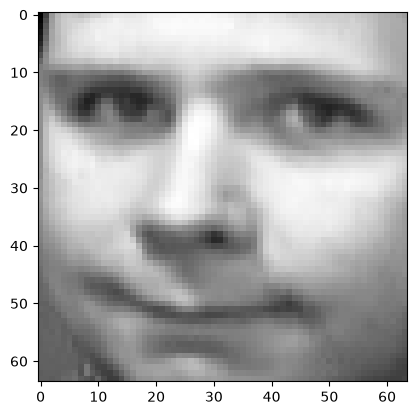

In [25]:
plt.imshow(images[0], cmap='gray')

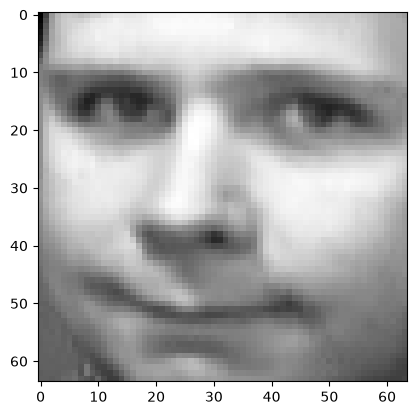

In [24]:
plt.imshow(X[0].reshape(64,64), cmap='gray')

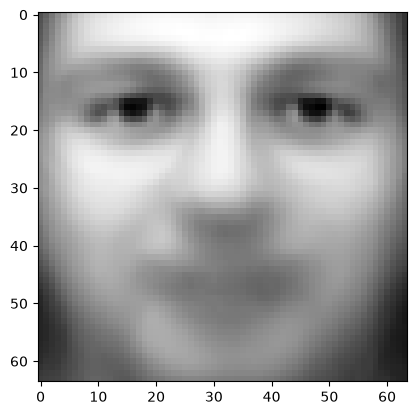

In [28]:
mean_face = X.mean(axis=0)

plt.imshow(mean_face.reshape(64,64), cmap='gray')

In [30]:
pca = PCA()
Z = pca.fit_transform(X)

In [31]:
Z.shape

(400, 400)

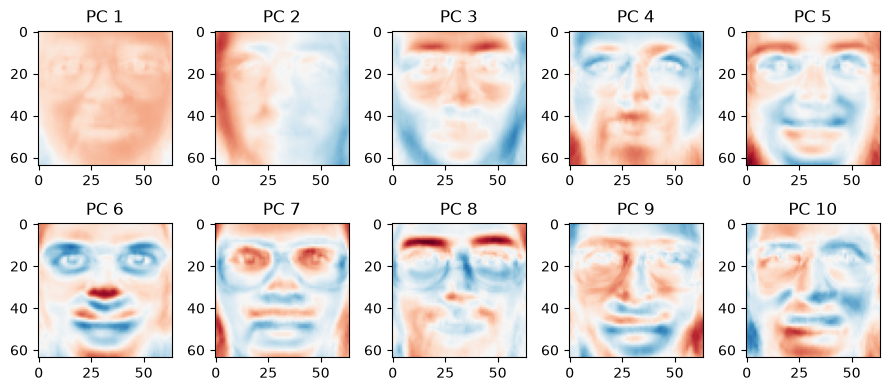

In [33]:
fig, axes = plt.subplots(2, 5, figsize = (9,4))
limit = np.abs(pca.components_[:10]).max()

for i, ax in enumerate(axes.flat):
    ax.imshow(pca.components_[i].reshape(64,64), cmap="RdBu_r", vmin= -limit, vmax=limit)
    ax.set_title(f"PC {i+1}")

plt.tight_layout()
plt.show()

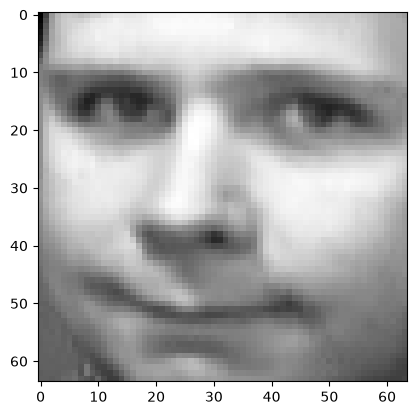

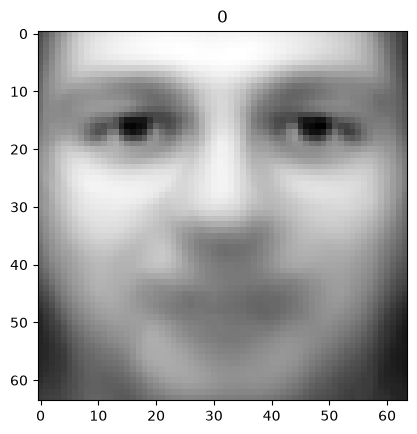

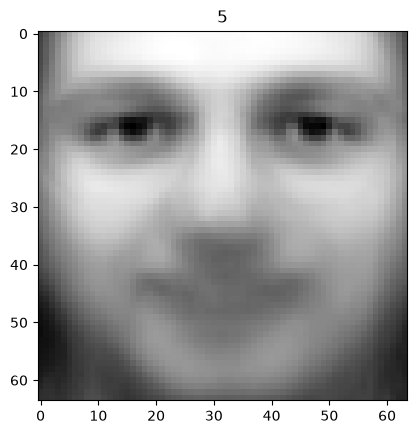

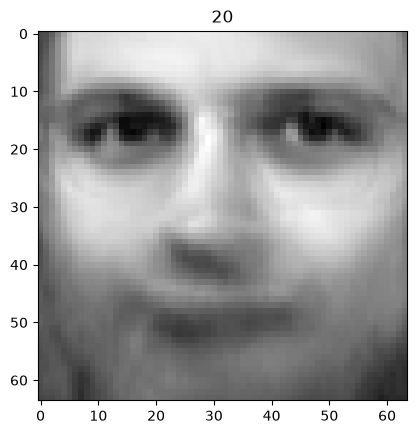

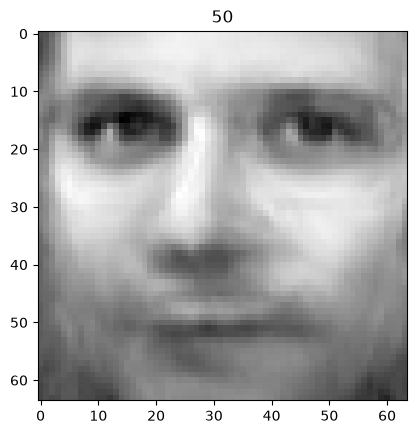

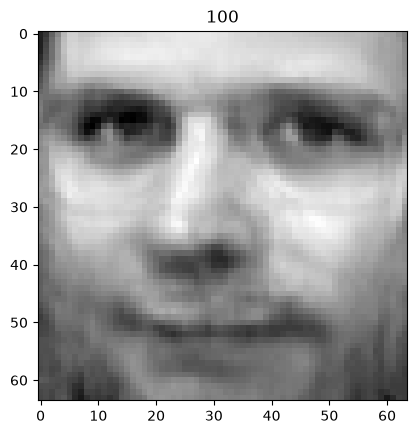

In [35]:
def reconstruct(k):
    return pca.mean_ + Z[:, :k] @ pca.components_[:k]

ks = [0, 5, 20, 50, 100]
i=0

plt.imshow(X[i].reshape(64,64), cmap='gray')
plt.show()
for k in ks:
    X_hat = reconstruct(k)
    plt.imshow(X_hat[i].reshape(64,64),  cmap="gray")
    plt.title(k)
    plt.show()